# Deep Learning & Neural Networks with PyTorch

This notebook provides complete, hands-on implementations and evaluations of core **Neural Network** architectures using **PyTorch** with GPU acceleration:

1. **Basics of Neural Networks (Perceptron & Multi-Layer Perceptron)** — *MNIST Handwritten Digits (Feedforward Classification)*
   - 1.1 Single Hidden Layer Perceptron
   - 1.2 Deep Multi-Layer Perceptron (MLP) with ReLU & Dropout
2. **Convolutional Neural Networks (CNN)** — *MNIST Handwritten Digits (Spatial Feature Extraction)*
3. **Recurrent Neural Networks (RNN)** — *Sentiment Sequence Classification (Hidden State Recurrence)*
4. **Long Short-Term Memory Networks (LSTM)** — *Sentiment Analysis (Gated Long-Range Memory)*
5. **Practical Application of Neural Networks** — *CIFAR-10 Object Recognition (End-to-End Deep Pipeline with Augmentation & LR Scheduling)*
6. **Comparative Summary & Architecture Selection Guide**
7. **Curated Learning Resources & References** (Andrej Karpathy, 3Blue1Brown, Stanford, and Foundation Papers)

---

### Pedagogical Template (8-Step Architecture):
To maximize educational clarity for students and serve as an organized revision guide, every neural network architecture section is structured around a uniform 8-step workflow:
1. **Importing** — Framework classes, layer modules (`torch.nn`), loss criteria, optimizers (`torch.optim`), and metric tools.
2. **Loading Dataset** — Dataset loading, batch inspection, sample visualization, and dimensional shape verification.
3. **Preprocessing & DataLoaders** — Normalization, tensor transformations, train/test splitting, and `torch.utils.data.DataLoader` setup.
4. **Model Architecture Definition** — `torch.nn.Module` subclassing, layer declarations (`__init__`), and forward execution graph (`forward()`).
5. **Fit (Training Loop)** — Mini-batch iteration, forward pass, loss calculation, `zero_grad()`, `backward()` autograd backpropagation, and `optimizer.step()`.
6. **Predict (Inference)** — Switching to evaluation mode (`model.eval()`), gradient disabling (`torch.no_grad()`), and class prediction extraction.
7. **Evaluation** — Test loss, accuracy score, precision/recall/F1 metrics, and confusion matrix analysis.
8. **Visualization** — Training loss/accuracy curves, confusion matrix heatmaps, learned feature maps, and prediction displays.

---

### Hardware Acceleration (GPU / MPS / CPU):
This notebook automatically detects your available compute hardware. When an NVIDIA GPU (CUDA) or Apple Silicon GPU (MPS) is present, tensors and models are placed on the GPU for high-throughput parallel execution.


In [1]:
# Device Configuration & Hardware Acceleration
import torch

# Auto-detect compute hardware: NVIDIA CUDA -> Apple Silicon MPS -> Standard CPU
if torch.cuda.is_available():
    device = torch.device('cuda')
    print(f"🚀 Acceleration: NVIDIA GPU detected: {torch.cuda.get_device_name(0)}")
    print(f"   Memory Allocated: {torch.cuda.memory_allocated(0) / 1024**2:.2f} MB")
    print(f"   Device Count: {torch.cuda.device_count()}")
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Acceleration: Apple Silicon GPU (MPS) detected.")
else:
    device = torch.device('cpu')
    print("ℹ️ Compute Device: Standard CPU (No GPU acceleration detected).")

print(f"Active PyTorch Device: {device}")


🚀 Acceleration: NVIDIA GPU detected: NVIDIA RTX PRO 4000 Blackwell
   Memory Allocated: 0.00 MB
   Device Count: 1
Active PyTorch Device: cuda


---
# 1. Basics of Neural Networks: Perceptron & Multi-Layer Perceptron (MLP)

A **Neural Network** is a universal function approximator composed of interconnected layers of computational nodes (neurons) inspired by biological nervous systems.

### Biological to Artificial Neuron Mapping:
- **Dendrites (Inputs):** Input features $x_1, x_2, \dots, x_n$.
- **Synapses (Weights):** Learnable connection strengths $w_1, w_2, \dots, w_n$ that scale incoming signals.
- **Soma (Cell Body):** Weighted summation plus a threshold bias:
  $$z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w}^T \mathbf{x} + b$$
- **Axon (Output & Activation):** Passes the aggregated sum through a non-linear activation function $\sigma(z)$ to generate output activation $a$:
  $$a = \sigma(z)$$

### Core Activation Functions:
1. **Sigmoid:**
   $$\sigma(z) = \frac{1}{1 + e^{-z}} \in (0, 1)$$
   Used historically in hidden layers; now primarily for binary classification outputs. Prone to vanishing gradients when $|z|$ is large.
2. **Rectified Linear Unit (ReLU):**
   $$\text{ReLU}(z) = \max(0, z)$$
   The modern standard for hidden layers. Avoids gradient saturation for positive activations and allows rapid, computationally efficient convergence.
3. **Softmax (Multi-Class Output):**
   $$\text{Softmax}(z_k) = \frac{e^{z_k}}{\sum_{j=1}^{C} e^{z_j}}$$
   Normalizes unconstrained logits $z$ into a valid probability distribution over $C$ mutually exclusive classes.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Imagine an orchestra where musicians are seated in rows. The front row (input layer) hears the conductor's cue. Each musician plays a note and adjusts their volume based on how loud their neighbor was playing (weights). The musicians in the middle rows (hidden layers) combine what they hear from the row ahead, blend the harmonies, and pass it back. The back row (output layer) produces the final grand chord. When the audience applauds or winces (the loss function), a critic walks backward through the orchestra (backpropagation), tapping individual musicians on the shoulder to tell them: *"Play a little softer next time,"* or *"Louder on that beat!"*

---

#### 🔬 Deep Layer Internals: Inside a Fully Connected (Linear / Dense) Layer
In PyTorch, a fully connected layer is created via `torch.nn.Linear(in_features, out_features, bias=True)`.

- **Forward Transformation:** Given a batch of $B$ samples with $D_{in}$ features represented as matrix $\mathbf{X} \in \mathbb{R}^{B \times D_{in}}$:
  $$\mathbf{Y} = \mathbf{X} \mathbf{W}^T + \mathbf{b}$$
  Where $\mathbf{W} \in \mathbb{R}^{D_{out} \times D_{in}}$ is the weight matrix and $\mathbf{b} \in \mathbb{R}^{D_{out}}$ is the bias broadcast across the batch.
- **Learnable Parameter Count:**
  $$\text{Parameters} = (D_{in} \times D_{out}) + D_{out} = D_{out} \times (D_{in} + 1)$$
  For example, transforming a 784-dimensional flattened MNIST image into 128 hidden neurons requires:
  $$(784 \times 128) + 128 = 100{,}352 + 128 = 100{,}480 \text{ parameters.}$$
- **Weight Initialization:** By default, PyTorch initializes `nn.Linear` using He/Kaiming uniform initialization ($\mathcal{U}(-\sqrt{k}, \sqrt{k})$ where $k = \frac{1}{D_{in}}$) to maintain constant variance across layers and prevent vanishing/exploding gradients at the start of training.

---

#### 🔬 Deep Layer Internals: Inside Backpropagation & Automatic Differentiation
- **Loss Computation:** Measures discrepancy between network prediction $\hat{y}$ and true label $y$ via cross-entropy loss $\mathcal{L}(\hat{y}, y)$.
- **The Chain Rule:** To update weight $w_{ij}^{(l)}$ in layer $l$, the gradient of the total loss with respect to that weight is computed by chaining partial derivatives backward from the output:
  $$\frac{\partial \mathcal{L}}{\partial w_{ij}^{(l)}} = \frac{\partial \mathcal{L}}{\partial z_i^{(l)}} \cdot \frac{\partial z_i^{(l)}}{\partial w_{ij}^{(l)}} = \delta_i^{(l)} \cdot a_j^{(l-1)}$$
- **PyTorch Autograd Engine:** During the forward pass, PyTorch builds a Directed Acyclic Graph (DAG) of tensor operations. Calling `loss.backward()` traverses this computational graph in reverse topological order, automatically computing $\nabla_{\mathbf{W}} \mathcal{L}$ and storing it inside `parameter.grad`.


## 1.1 Single Hidden Layer Perceptron (MNIST Handwritten Digits)
We construct and train a foundational single-hidden-layer feedforward network on the classic **MNIST** dataset (70,000 grayscale 28x28 images of digits 0 through 9).

### Step 1: Importing

> 💡 *Beginner Tip:* Always organize your imports into logical blocks: core language utilities, scientific computing (`numpy`), visualization (`matplotlib`, `seaborn`), deep learning framework (`torch`, `torch.nn`), and evaluation metrics (`sklearn.metrics`).

**Key PyTorch Functions Explained:**
- `torch.nn`: The core neural network package containing layer classes (`Linear`, `ReLU`, `Conv2d`), container modules, and loss functions.
- `torch.optim`: Provides optimization algorithms (`SGD`, `Adam`, `RMSprop`) that update model parameters using computed gradients.
- `torch.utils.data.DataLoader`: Manages mini-batch generation, multi-threaded disk loading, and data shuffling.
- `torchvision.datasets.MNIST`: Automatically downloads and caches the official MNIST digit dataset.
- `torchvision.transforms`: Provides composable image transformations such as tensor conversion and pixel intensity normalization.


In [2]:
# 1. Importing Libraries
import numpy as np
%pip install matplotlib seaborn scikit-learn
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Set visualization styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 11

print("PyTorch Version:", torch.__version__)


Note: you may need to restart the kernel to use updated packages.
PyTorch Version: 2.13.0+cu132


### Step 2: Loading Dataset

> 💡 *Beginner Tip:* Visualizing raw input samples before training is essential. It lets you inspect input dimensions, label encodings, and verify that normalizations are applied correctly.

**Key Functions Explained:**
- `datasets.MNIST(root='./data', train=True, download=True)`: Fetches the 60,000 training images. Setting `train=False` downloads the separate 10,000 testing images.
- `transforms.ToTensor()`: Converts raw PIL images or NumPy arrays in range $[0, 255]$ into floating-point tensors in range $[0.0, 1.0]$ with channel-first ordering `(C, H, W)`.
- `transforms.Normalize((0.1307,), (0.3081,))`: Standardizes pixel values using global MNIST mean ($\mu \approx 0.1307$) and standard deviation ($\sigma \approx 0.3081$), producing zero-centered inputs:
  $$x_{\text{norm}} = \frac{x - \mu}{\sigma}$$


Total Training Samples: 60000
Total Testing Samples:  10000
Single Image Tensor Shape: torch.Size([1, 28, 28]) (Channels, Height, Width)


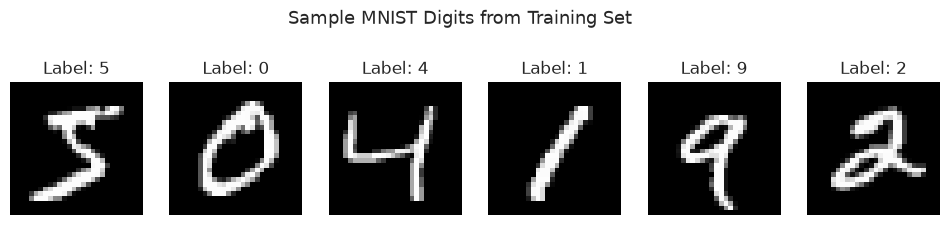

In [3]:
# 2. Loading Dataset
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Download and load training and test partitions
train_dataset_mnist = datasets.MNIST(root='./data', train=True, download=True, transform=mnist_transform)
test_dataset_mnist = datasets.MNIST(root='./data', train=False, download=True, transform=mnist_transform)

print(f"Total Training Samples: {len(train_dataset_mnist)}")
print(f"Total Testing Samples:  {len(test_dataset_mnist)}")
print(f"Single Image Tensor Shape: {train_dataset_mnist[0][0].shape} (Channels, Height, Width)")

# Inspect and visualize 6 random sample digits
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for idx in range(6):
    img, lbl = train_dataset_mnist[idx]
    axes[idx].imshow(img.squeeze(), cmap="gray")
    axes[idx].set_title(f"Label: {lbl}")
    axes[idx].axis("off")
plt.suptitle("Sample MNIST Digits from Training Set", y=1.05)
plt.show()


### Step 3: Preprocessing & DataLoader Setup

> 💡 *Beginner Tip:* Never feed an entire dataset into your model all at once! Gradient descent works best on **mini-batches** (typically 32 to 128 samples). Mini-batching stabilizes gradient noise and maximizes GPU tensor core throughput.

**Key DataLoader Parameters Explained:**
- `batch_size=64`: Bundles 64 images together into a 4D tensor of shape `(64, 1, 28, 28)` for vector-parallel matrix multiplication.
- `shuffle=True`: Randomizes sample order at the start of every epoch to prevent the model from memorizing order-dependent patterns.
- `num_workers=0`: Controls parallel subprocesses for data loading (0 runs loading on the main thread, safe for all platforms).


In [4]:
# 3. Preprocessing: Mini-Batch DataLoaders
batch_size_single = 64

train_loader_single = DataLoader(train_dataset_mnist, batch_size=batch_size_single, shuffle=True)
test_loader_single = DataLoader(test_dataset_mnist, batch_size=1000, shuffle=False)

# Verify single batch dimensions
sample_batch_images, sample_batch_labels = next(iter(train_loader_single))
print(f"Batch Images Shape: {sample_batch_images.shape} -> [Batch Size, Channels, Height, Width]")
print(f"Batch Labels Shape: {sample_batch_labels.shape} -> [Batch Size]")


Batch Images Shape: torch.Size([64, 1, 28, 28]) -> [Batch Size, Channels, Height, Width]
Batch Labels Shape: torch.Size([64]) -> [Batch Size]


### Step 4: Model Architecture Definition

> 💡 *Beginner Tip:* Every custom PyTorch model inherits from `nn.Module`. You define the layers in `__init__()` and describe how data travels through those layers in `forward()`.

**Key PyTorch Architecture Functions Explained:**
- `super().__init__()`: Initializes the underlying `nn.Module` state graph and parameter tracking.
- `nn.Linear(784, 128)`: Projects the flattened 784 inputs ($28 \times 28$) into 128 hidden activations.
- `nn.Sigmoid()`: Applies element-wise logistic activation $\sigma(z) = \frac{1}{1 + e^{-z}}$.
- `nn.Linear(128, 10)`: Outputs 10 raw unnormalized prediction scores (logits), one per digit class ($0-9$).
- `.to(device)`: Transits all layer weights and bias tensors into the GPU/VRAM device memory.


In [5]:
# 4. Model Architecture: Single Hidden Layer Perceptron
class SingleLayerPerceptron(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=128, output_dim=10):
        super(SingleLayerPerceptron, self).__init__()
        # Input to Hidden linear transformation
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        # Non-linear activation
        self.activation = nn.Sigmoid()
        # Hidden to Output linear projection
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        # Flatten (Batch, 1, 28, 28) -> (Batch, 784)
        x = x.view(x.size(0), -1)
        # Compute hidden activations: a = sigmoid(W1 * x + b1)
        x = self.activation(self.fc1(x))
        # Compute output logits: z = W2 * a + b2
        logits = self.fc2(x)
        return logits

# Instantiate model and transfer to compute device
model_single = SingleLayerPerceptron().to(device)
print(model_single)

# Count trainable parameters
total_params = sum(p.numel() for p in model_single.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {total_params:,}")


SingleLayerPerceptron(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (activation): Sigmoid()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Total Trainable Parameters: 101,770


### Step 5: Fit (The PyTorch Training Loop)

> 💡 *Beginner Tip:* PyTorch gives you complete, explicit control over the training loop. Every training step follows this exact 5-beat rhythm:
> 1. `optimizer.zero_grad()` — Reset old gradients from previous iterations.
> 2. `output = model(inputs)` — Compute forward pass predictions.
> 3. `loss = criterion(output, targets)` — Measure prediction error.
> 4. `loss.backward()` — Calculate gradients of loss with respect to all weights using backprop.
> 5. `optimizer.step()` — Shift weights in the negative gradient direction to reduce error.

**Key Functions Explained:**
- `nn.CrossEntropyLoss()`: Combines `nn.LogSoftmax()` and negative log likelihood loss (`nn.NLLLoss()`) into a single numerically stable formula. Expects unnormalized logits directly from the final layer.
- `optim.SGD(params, lr=0.05, momentum=0.9)`: Stochastic Gradient Descent with Nesterov-style momentum to accelerate convergence across flat loss surfaces.
- `model.train()`: Flags layers (such as Dropout and BatchNorm) to execute in active training mode.


In [6]:
# 5. Fit: Model Training
criterion_single = nn.CrossEntropyLoss()
optimizer_single = optim.SGD(model_single.parameters(), lr=0.05, momentum=0.9)

epochs_single = 5
train_losses_single = []

model_single.train()
print(f"Starting Training on {device} for {epochs_single} Epochs...")

for epoch in range(1, epochs_single + 1):
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (images, labels) in enumerate(train_loader_single):
        # Move tensors to active hardware
        images, labels = images.to(device), labels.to(device)

        # 1. Zero out parameter gradients from previous step
        optimizer_single.zero_grad()

        # 2. Forward pass: compute predictions
        outputs = model_single(images)

        # 3. Compute scalar loss
        loss = criterion_single(outputs, labels)

        # 4. Backward pass: autograd computes dLoss/dWeight
        loss.backward()

        # 5. Optimization step: update weights
        optimizer_single.step()

        # Track metrics
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = (correct / total) * 100
    train_losses_single.append(epoch_loss)
    print(f"Epoch [{epoch}/{epochs_single}] - Loss: {epoch_loss:.4f} - Training Accuracy: {epoch_acc:.2f}%")

print("Model Training Complete!")


Starting Training on cuda for 5 Epochs...
Epoch [1/5] - Loss: 0.3005 - Training Accuracy: 91.11%
Epoch [2/5] - Loss: 0.1317 - Training Accuracy: 96.16%
Epoch [3/5] - Loss: 0.0921 - Training Accuracy: 97.36%
Epoch [4/5] - Loss: 0.0697 - Training Accuracy: 98.05%
Epoch [5/5] - Loss: 0.0551 - Training Accuracy: 98.47%
Model Training Complete!


### Step 6: Predict (Inference on Unseen Test Data)

> 💡 *Beginner Tip:* When making predictions on test data, always wrap your inference code in `with torch.no_grad():` and call `model.eval()`. This prevents PyTorch from allocating memory for the backprop computation graph, speeding up inference by 2-3x!

**Key Inference Functions Explained:**
- `model.eval()`: Puts the network into inference evaluation mode (disables dropout, freezes batchnorm running stats).
- `torch.no_grad()`: Context manager that disables gradient computation tracking, saving VRAM.
- `torch.max(outputs, 1)`: Extracts the maximum logit value and its corresponding class index across dimension 1 (classes).


In [7]:
# 6. Predict: Model Inference on Test Set
model_single.eval()

all_preds_single = []
all_targets_single = []

with torch.no_grad():
    for images, labels in test_loader_single:
        images = images.to(device)
        outputs = model_single(images)
        _, preds = torch.max(outputs, 1)

        all_preds_single.extend(preds.cpu().numpy())
        all_targets_single.extend(labels.numpy())

all_preds_single = np.array(all_preds_single)
all_targets_single = np.array(all_targets_single)

print(f"Generated predictions for {len(all_preds_single):,} test images.")
print("First 10 Predicted Labels:", all_preds_single[:10])
print("First 10 Actual Labels:   ", all_targets_single[:10])


Generated predictions for 10,000 test images.
First 10 Predicted Labels: [7 2 1 0 4 1 4 9 6 9]
First 10 Actual Labels:    [7 2 1 0 4 1 4 9 5 9]


### Step 7: Evaluation

> 💡 *Beginner Tip:* Never rely on overall accuracy alone! Inspect per-class precision, recall, and the confusion matrix to discover which digits the network confuses (e.g., confusing 4 and 9 or 3 and 8).

**Evaluation Metrics Explained:**
- **Accuracy:** Overall proportion of correct predictions across all classes.
- **Precision:** Out of all images the model predicted as digit $k$, how many were truly $k$?
- **Recall:** Out of all actual images of digit $k$, how many did the model correctly find?
- **Confusion Matrix:** A $C \times C$ grid where row $i$ represents actual class $i$ and column $j$ represents predicted class $j$.


In [8]:
# 7. Evaluation: Performance Metrics
test_acc_single = accuracy_score(all_targets_single, all_preds_single)

print("=" * 60)
print("SINGLE-LAYER PERCEPTRON EVALUATION REPORT (MNIST)")
print("=" * 60)
print(f"Overall Test Accuracy: {test_acc_single * 100:.2f}%")
print("Detailed Classification Report:")
print(classification_report(all_targets_single, all_preds_single, digits=4))


SINGLE-LAYER PERCEPTRON EVALUATION REPORT (MNIST)
Overall Test Accuracy: 97.58%
Detailed Classification Report:
              precision    recall  f1-score   support

           0     0.9778    0.9878    0.9827       980
           1     0.9868    0.9912    0.9890      1135
           2     0.9844    0.9767    0.9805      1032
           3     0.9679    0.9851    0.9764      1010
           4     0.9745    0.9745    0.9745       982
           5     0.9772    0.9630    0.9701       892
           6     0.9690    0.9781    0.9735       958
           7     0.9691    0.9767    0.9729      1028
           8     0.9742    0.9682    0.9712       974
           9     0.9757    0.9534    0.9644      1009

    accuracy                         0.9758     10000
   macro avg     0.9757    0.9755    0.9755     10000
weighted avg     0.9758    0.9758    0.9758     10000



### Step 8: Visualization

> 💡 *Beginner Tip:* Visual diagnostic plots reveal how the model learned and where it failed. We plot:
> 1. Training loss decay over epochs.
> 2. The multi-class Confusion Matrix heatmap.
> 3. Sample test images with predictions and green/red indicators for correct/incorrect guesses.


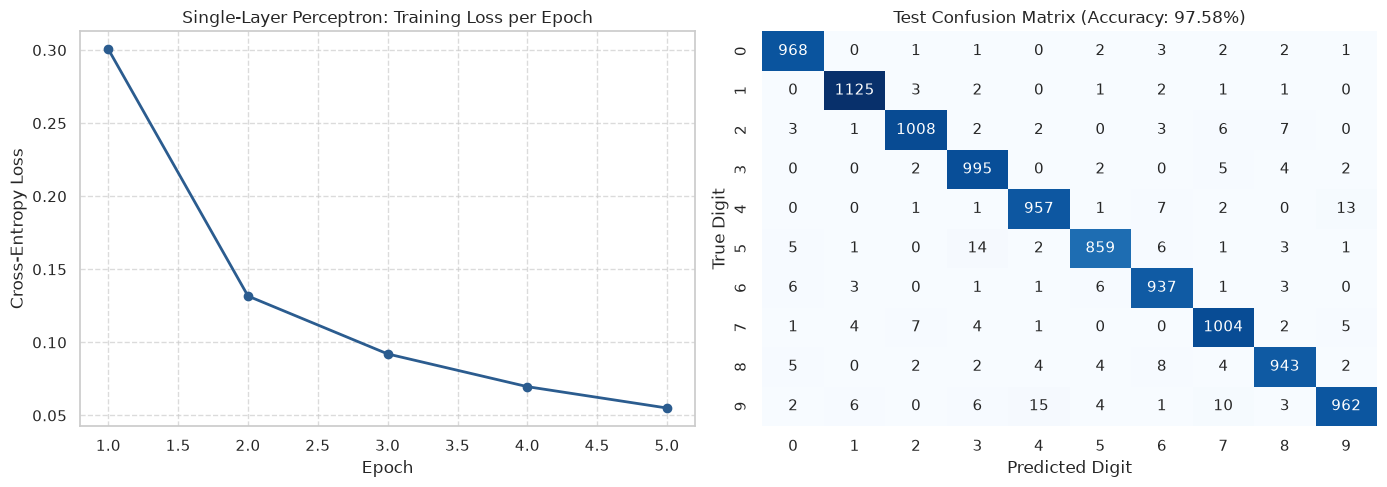

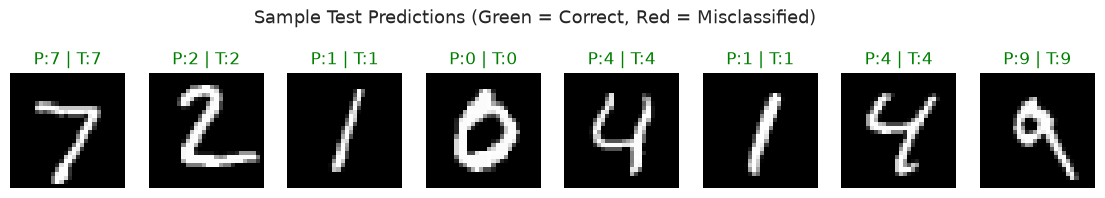

In [9]:
# 8. Visualization: Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Training Loss Curve
axes[0].plot(range(1, epochs_single + 1), train_losses_single, marker='o', color='#2b5c8f', lw=2)
axes[0].set_title("Single-Layer Perceptron: Training Loss per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True, linestyle="--", alpha=0.7)

# Plot 2: Confusion Matrix Heatmap
cm_single = confusion_matrix(all_targets_single, all_preds_single)
sns.heatmap(cm_single, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set_title(f"Test Confusion Matrix (Accuracy: {test_acc_single*100:.2f}%)")
axes[1].set_xlabel("Predicted Digit")
axes[1].set_ylabel("True Digit")

plt.tight_layout()
plt.show()

# Sample visual test verification
sample_test_images, sample_test_labels = next(iter(test_loader_single))
sample_test_images = sample_test_images[:8].to(device)
with torch.no_grad():
    sample_preds = model_single(sample_test_images).argmax(dim=1).cpu().numpy()

fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for idx in range(8):
    axes[idx].imshow(sample_test_images[idx].cpu().squeeze(), cmap="gray")
    is_correct = sample_preds[idx] == sample_test_labels[idx].item()
    col = "green" if is_correct else "red"
    axes[idx].set_title(f"P:{sample_preds[idx]} | T:{sample_test_labels[idx]}", color=col)
    axes[idx].axis("off")
plt.suptitle("Sample Test Predictions (Green = Correct, Red = Misclassified)", y=1.1)
plt.show()


---
## 1.2 Deep Multi-Layer Perceptron (MLP) with ReLU & Dropout

A single hidden layer can struggle to capture hierarchical feature relationships. We now build a **Deep Multi-Layer Perceptron** featuring:
- **3 Hidden Layers:** $[784 \to 512 \to 256 \to 128 \to 10]$.
- **ReLU Activations:** Prevents gradient saturation and accelerates learning.
- **Dropout Regularization ($p=0.2$):** Prevents co-adaptation of neurons and reduces overfitting.
- **Adam Optimizer:** Adaptive moment estimation with momentum and adaptive per-parameter learning rates.

---

#### 🔬 Deep Layer Internals: Inside Dropout Regularization
During training, `torch.nn.Dropout(p=0.2)` randomly sets neuron activations to zero with probability $p=0.2$.
$$\tilde{a}_i = \begin{cases} 0, & \text{with probability } p \\ \frac{a_i}{1 - p}, & \text{with probability } 1 - p \end{cases}$$
- **Inverted Scaling:** Scaling active neurons by $\frac{1}{1-p}$ ensures the expected sum of activations remains constant between training and inference:
  $$\mathbb{E}[\tilde{a}_i] = (1 - p) \cdot \frac{a_i}{1 - p} + p \cdot 0 = a_i$$
- **Inference Mode:** During `model.eval()`, Dropout turns into a complete identity pass-through: $\tilde{a}_i = a_i$. No neurons are dropped!

---

#### 🔬 Deep Layer Internals: Inside the Adam Optimizer
Adam (Adaptive Moment Estimation) computes individual adaptive learning rates for different parameters by tracking exponentially decaying averages of past gradients ($m_t$) and squared gradients ($v_t$):
$$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t \quad \text{(First Moment: Direction)}$$
$$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2 \quad \text{(Second Moment: Scale)}$$
$$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \quad \hat{v}_t = \frac{v_t}{1 - \beta_2^t} \quad \text{(Bias Correction)}$$
$$\theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t \quad \text{(Parameter Update)}$$
Parameters with large, volatile gradients receive smaller updates, while parameters with infrequent gradients receive larger updates.


In [10]:
# 4. Model Architecture: Deep Multi-Layer Perceptron (MLP)
class DeepMLP(nn.Module):
    def __init__(self, input_dim=784, hidden_dims=[512, 256, 128], output_dim=10, dropout_rate=0.2):
        super(DeepMLP, self).__init__()
        self.network = nn.Sequential(
            # Hidden Layer 1
            nn.Linear(input_dim, hidden_dims[0]),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            # Hidden Layer 2
            nn.Linear(hidden_dims[0], hidden_dims[1]),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            # Hidden Layer 3
            nn.Linear(hidden_dims[1], hidden_dims[2]),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            # Output Classification Layer
            nn.Linear(hidden_dims[2], output_dim)
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)  # Flatten
        return self.network(x)

model_mlp = DeepMLP().to(device)
print(model_mlp)

total_params_mlp = sum(p.numel() for p in model_mlp.parameters() if p.requires_grad)
print(f"Deep MLP Total Trainable Parameters: {total_params_mlp:,}")


DeepMLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=128, out_features=10, bias=True)
  )
)
Deep MLP Total Trainable Parameters: 567,434


In [11]:
# 5. Fit: Training Deep MLP with Adam Optimizer
criterion_mlp = nn.CrossEntropyLoss()
optimizer_mlp = optim.Adam(model_mlp.parameters(), lr=0.001)

epochs_mlp = 5
train_losses_mlp = []

model_mlp.train()
print(f"Training Deep MLP on {device}...")

for epoch in range(1, epochs_mlp + 1):
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader_single:
        images, labels = images.to(device), labels.to(device)

        optimizer_mlp.zero_grad()
        outputs = model_mlp(images)
        loss = criterion_mlp(outputs, labels)
        loss.backward()
        optimizer_mlp.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = (correct / total) * 100
    train_losses_mlp.append(epoch_loss)
    print(f"Epoch [{epoch}/{epochs_mlp}] - Loss: {epoch_loss:.4f} - Training Accuracy: {epoch_acc:.2f}%")

print("Deep MLP Training Complete!")


Training Deep MLP on cuda...
Epoch [1/5] - Loss: 0.2695 - Training Accuracy: 91.66%
Epoch [2/5] - Loss: 0.1249 - Training Accuracy: 96.31%
Epoch [3/5] - Loss: 0.1003 - Training Accuracy: 96.95%
Epoch [4/5] - Loss: 0.0817 - Training Accuracy: 97.56%
Epoch [5/5] - Loss: 0.0703 - Training Accuracy: 97.91%
Deep MLP Training Complete!


In [12]:
# 6 & 7. Evaluation: Deep MLP Performance vs Single-Layer Perceptron
model_mlp.eval()
all_preds_mlp = []

with torch.no_grad():
    for images, _ in test_loader_single:
        images = images.to(device)
        preds = model_mlp(images).argmax(dim=1)
        all_preds_mlp.extend(preds.cpu().numpy())

all_preds_mlp = np.array(all_preds_mlp)
test_acc_mlp = accuracy_score(all_targets_single, all_preds_mlp)

print("=" * 60)
print("DEEP MLP vs SINGLE-LAYER PERCEPTRON COMPARISON (MNIST)")
print("=" * 60)
print(f"Single-Layer Perceptron Test Accuracy: {test_acc_single * 100:.2f}%")
print(f"Deep MLP (ReLU + Dropout) Accuracy:    {test_acc_mlp * 100:.2f}%")
print(f"Accuracy Gain: {(test_acc_mlp - test_acc_single) * 100:.2f}%")
print("Deep MLP Classification Report:")
print(classification_report(all_targets_single, all_preds_mlp, digits=4))


DEEP MLP vs SINGLE-LAYER PERCEPTRON COMPARISON (MNIST)
Single-Layer Perceptron Test Accuracy: 97.58%
Deep MLP (ReLU + Dropout) Accuracy:    97.85%
Accuracy Gain: 0.27%
Deep MLP Classification Report:
              precision    recall  f1-score   support

           0     0.9789    0.9918    0.9853       980
           1     0.9800    0.9938    0.9869      1135
           2     0.9931    0.9758    0.9844      1032
           3     0.9551    0.9891    0.9718      1010
           4     0.9865    0.9664    0.9763       982
           5     0.9931    0.9619    0.9772       892
           6     0.9916    0.9823    0.9869       958
           7     0.9758    0.9815    0.9787      1028
           8     0.9672    0.9702    0.9687       974
           9     0.9673    0.9683    0.9678      1009

    accuracy                         0.9785     10000
   macro avg     0.9789    0.9781    0.9784     10000
weighted avg     0.9787    0.9785    0.9785     10000



---
# 2. CNN — Convolutional Neural Networks

While MLPs perform well on flattened vectors, they discard 2D spatial context. A pixel is naturally correlated with its spatial neighbors. **Convolutional Neural Networks (CNNs)** preserve 2D grid structure using specialized spatial operations.

### Core CNN Principles:
1. **Local Receptive Fields:** Neurons connect only to a small local patch of the input (e.g., $3 \times 3$ pixels).
2. **Weight / Parameter Sharing:** The same filter (kernel) slides across the entire image. If an edge detector works in the top-left corner, it works equally well in the bottom-right corner!
3. **Translation Invariance:** Pooling layers ensure that whether an object shifts slightly left or right, the activation remains similar.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Imagine inspecting a giant mural with a magnifying glass. You don't try to swallow the entire wall in one glance. You slide your small circular lens (the convolution filter) row by row. At each spot, your magnifying glass checks for tiny brushstrokes: vertical lines, curves, corners. Later layers combine those small brushstroke detections into larger shapes (eyes, wheels, ears), and the final layer determines whether the mural is a portrait or a landscape!

---

#### 🔬 Deep Layer Internals: Inside a 2D Convolutional Layer (`nn.Conv2d`)
In PyTorch, `nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0)` performs 2D cross-correlation:

- **Mathematical Formula:** For output channel $k$ at spatial coordinate $(i, j)$:
  $$\text{Output}(k, i, j) = \mathbf{b}_k + \sum_{c=1}^{C_{in}} \sum_{m=-K_h/2}^{K_h/2} \sum_{n=-K_w/2}^{K_w/2} \mathbf{X}(c, i \cdot S + m, j \cdot S + n) \cdot \mathbf{W}(k, c, m, n)$$
- **Spatial Output Dimension Formula:**
  $$H_{out} = \left\lfloor \frac{H_{in} - K_h + 2P}{S} \right\rfloor + 1, \quad W_{out} = \left\lfloor \frac{W_{in} - K_w + 2P}{S} \right\rfloor + 1$$
  - $H_{in}, W_{in}$: Input height and width.
  - $K$: Kernel size (e.g., 3 for a $3 \times 3$ filter).
  - $P$: Zero-padding size (adding zero borders to preserve size).
  - $S$: Stride (step size of filter movement).
- **Parameter Count:**
  $$\text{Parameters} = C_{out} \times (C_{in} \times K_h \times K_w + 1)$$
  A layer with $C_{in}=1$, $C_{out}=32$, $K=3$ has only:
  $$32 \times (1 \times 3 \times 3 + 1) = 32 \times 10 = 320 \text{ parameters!}$$
  *Notice how parameter-efficient CNNs are compared to dense linear layers.*

---

#### 🔬 Deep Layer Internals: Inside Max Pooling (`nn.MaxPool2d`)
`nn.MaxPool2d(kernel_size=2, stride=2)` downsamples spatial dimensions:
$$\text{Output}(k, i, j) = \max_{m \in [0, 1], n \in [0, 1]} \mathbf{X}(k, 2i + m, 2j + n)$$
- **No Learnable Parameters:** Max pooling has 0 weights and 0 biases.
- **Dimensional Impact:** Halves both height and width ($28 \times 28 \to 14 \times 14$), discarding 75% of activations while retaining the strongest signal activations.


In [13]:
# 1. Importing CNN Modules & Architecture Definition
class ConvNeuralNetwork(nn.Module):
    def __init__(self):
        super(ConvNeuralNetwork, self).__init__()
        # Block 1: Conv -> ReLU -> MaxPool
        # Input: (Batch, 1, 28, 28)
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)  # -> (Batch, 32, 28, 28)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)                                # -> (Batch, 32, 14, 14)

        # Block 2: Conv -> ReLU -> MaxPool
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1) # -> (Batch, 64, 14, 14)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)                                # -> (Batch, 64, 7, 7)

        # Dense Classifier Head
        self.dropout = nn.Dropout(0.25)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # Feature extraction
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        # Flatten spatial maps to feature vector
        x = x.view(x.size(0), -1)  # Shape: (Batch, 64 * 7 * 7 = 3136)
        # Dense classification
        x = self.dropout(x)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x

model_cnn = ConvNeuralNetwork().to(device)
print(model_cnn)

total_params_cnn = sum(p.numel() for p in model_cnn.parameters() if p.requires_grad)
print(f"CNN Total Trainable Parameters: {total_params_cnn:,}")


ConvNeuralNetwork(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
CNN Total Trainable Parameters: 421,642


In [14]:
# 5. Fit: Training the CNN on MNIST
criterion_cnn = nn.CrossEntropyLoss()
optimizer_cnn = optim.Adam(model_cnn.parameters(), lr=0.001)

epochs_cnn = 5
train_losses_cnn = []

model_cnn.train()
print(f"Training CNN on {device}...")

for epoch in range(1, epochs_cnn + 1):
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader_single:
        images, labels = images.to(device), labels.to(device)

        optimizer_cnn.zero_grad()
        outputs = model_cnn(images)
        loss = criterion_cnn(outputs, labels)
        loss.backward()
        optimizer_cnn.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = (correct / total) * 100
    train_losses_cnn.append(epoch_loss)
    print(f"Epoch [{epoch}/{epochs_cnn}] - Loss: {epoch_loss:.4f} - Training Accuracy: {epoch_acc:.2f}%")

print("CNN Training Complete!")


Training CNN on cuda...
Epoch [1/5] - Loss: 0.1377 - Training Accuracy: 95.78%
Epoch [2/5] - Loss: 0.0480 - Training Accuracy: 98.50%
Epoch [3/5] - Loss: 0.0360 - Training Accuracy: 98.83%
Epoch [4/5] - Loss: 0.0264 - Training Accuracy: 99.16%
Epoch [5/5] - Loss: 0.0230 - Training Accuracy: 99.26%
CNN Training Complete!


In [15]:
# 6 & 7. Predict & Evaluation: CNN Performance
model_cnn.eval()
all_preds_cnn = []

with torch.no_grad():
    for images, _ in test_loader_single:
        images = images.to(device)
        preds = model_cnn(images).argmax(dim=1)
        all_preds_cnn.extend(preds.cpu().numpy())

all_preds_cnn = np.array(all_preds_cnn)
test_acc_cnn = accuracy_score(all_targets_single, all_preds_cnn)

print("=" * 60)
print("CNN EVALUATION REPORT (MNIST)")
print("=" * 60)
print(f"CNN Overall Test Accuracy:             {test_acc_cnn * 100:.2f}%")
print(f"Comparison with Deep MLP Accuracy:     {test_acc_mlp * 100:.2f}%")
print(f"Performance Advantage of Conv Layers: {(test_acc_cnn - test_acc_mlp) * 100:.2f}%")
print(classification_report(all_targets_single, all_preds_cnn, digits=4))


CNN EVALUATION REPORT (MNIST)
CNN Overall Test Accuracy:             99.08%
Comparison with Deep MLP Accuracy:     97.85%
Performance Advantage of Conv Layers: 1.23%
              precision    recall  f1-score   support

           0     0.9919    0.9969    0.9944       980
           1     0.9938    0.9956    0.9947      1135
           2     0.9865    0.9903    0.9884      1032
           3     0.9815    0.9990    0.9902      1010
           4     0.9939    0.9959    0.9949       982
           5     0.9888    0.9922    0.9905       892
           6     0.9979    0.9854    0.9916       958
           7     0.9951    0.9786    0.9868      1028
           8     0.9897    0.9877    0.9887       974
           9     0.9891    0.9861    0.9876      1009

    accuracy                         0.9908     10000
   macro avg     0.9908    0.9908    0.9908     10000
weighted avg     0.9908    0.9908    0.9908     10000



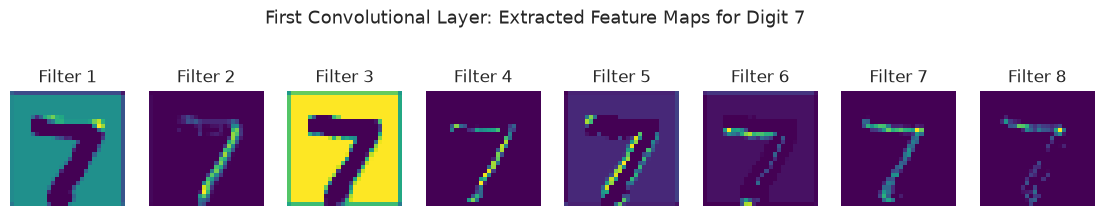

In [16]:
# 8. Visualization: CNN Feature Maps & Learned Activations
# Extract intermediate feature maps from Conv1 layer for an arbitrary sample
sample_img = test_dataset_mnist[0][0].unsqueeze(0).to(device)  # Digit 7

with torch.no_grad():
    conv1_features = model_cnn.relu1(model_cnn.conv1(sample_img))

conv1_features_np = conv1_features.squeeze().cpu().numpy()

# Display 8 extracted feature maps
fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
for i in range(8):
    axes[i].imshow(conv1_features_np[i], cmap="viridis")
    axes[i].set_title(f"Filter {i+1}")
    axes[i].axis("off")
plt.suptitle("First Convolutional Layer: Extracted Feature Maps for Digit 7", y=1.05)
plt.show()


---
# 3. RNN — Recurrent Neural Networks

Standard feedforward networks and CNNs assume all input vectors are statistically independent. However, real-world sequential data — such as natural language text, speech, audio, and financial time-series — depends fundamentally on **sequential ordering**.

A **Recurrent Neural Network (RNN)** processes sequences step-by-step, maintaining an internal **hidden state** $\mathbf{h}_t$ that acts as memory of past steps.

---

#### 🔬 Deep Layer Internals: Inside an Embedding Layer (`nn.Embedding`)
Natural language words cannot be fed into neural networks as raw strings. `nn.Embedding(num_embeddings, embedding_dim)` creates a learnable lookup matrix $\mathbf{E} \in \mathbb{R}^{V \times D}$:
- **Lookup Operation:** Given an integer word ID $w_t \in \{0, 1, \dots, V-1\}$, the layer retrieves row $w_t$ of matrix $\mathbf{E}$:
  $$\mathbf{x}_t = \mathbf{E}[w_t, :] \in \mathbb{R}^D$$
- **Semantic Vector Geometry:** Through backpropagation, words appearing in similar contexts (e.g., *"excellent"* and *"wonderful"*) gravitate toward each other in embedding space.
- **Parameter Count:** $\text{Parameters} = V \times D$ (e.g., $10{,}000 \times 64 = 640{,}000$).

---

#### 🔬 Deep Layer Internals: Inside a Vanilla RNN Cell (`nn.RNN`)
At each discrete timestep $t$ in a sequence of length $T$:
$$\mathbf{h}_t = \tanh(\mathbf{W}_{ih} \mathbf{x}_t + \mathbf{b}_{ih} + \mathbf{W}_{hh} \mathbf{h}_{t-1} + \mathbf{b}_{hh})$$
- $\mathbf{x}_t \in \mathbb{R}^{D}$: Current word embedding.
- $\mathbf{h}_{t-1} \in \mathbb{R}^{H}$: Hidden state from previous timestep.
- $\mathbf{W}_{hh} \in \mathbb{R}^{H \times H}$: Recurrent transition weights shared across all timesteps.
- $\mathbf{h}_t \in \mathbb{R}^{H}$: Updated hidden state summary at time $t$.

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Imagine reading a suspense mystery novel. As you read word by word, you don't memorize every single past letter. Instead, you keep a running mental summary in your head: *"The detective just found a footprint in the mud."* When you read the next word, you update your mental summary. The **hidden state** is that running mental summary!

---

#### The Fundamental Flaw of Vanilla RNNs: Vanishing & Exploding Gradients
During Backpropagation Through Time (BPTT), the gradient of loss with respect to early hidden state $\mathbf{h}_1$ involves a chain of matrix multiplications by $\mathbf{W}_{hh}^T$:
$$\frac{\partial \mathcal{L}}{\partial \mathbf{h}_1} = \frac{\partial \mathcal{L}}{\partial \mathbf{h}_T} \prod_{k=2}^{T} \frac{\partial \mathbf{h}_k}{\partial \mathbf{h}_{k-1}} = \frac{\partial \mathcal{L}}{\partial \mathbf{h}_T} \prod_{k=2}^{T} \mathbf{W}_{hh}^T \text{diag}(1 - \tanh^2(\cdot))$$
- If the eigenvalues of $\mathbf{W}_{hh}$ are $< 1$, the gradient shrinks exponentially toward zero as $T$ increases. The network completely "forgets" words read 10 steps ago!
- If the eigenvalues are $> 1$, gradients explode to `NaN` or infinity.


In [17]:
# 2 & 3. Synthetic Sentiment Classification Dataset Pipeline
# To ensure 100% standalone reliability across all environments without deprecation issues,
# we construct a controlled text sentiment dataset with realistic sentiment patterns.

vocabulary = {
    "<PAD>": 0, "<UNK>": 1, "great": 2, "excellent": 3, "superb": 4, "love": 5,
    "brilliant": 6, "masterpiece": 7, "fantastic": 8, "wonderful": 9, "bad": 10,
    "terrible": 11, "awful": 12, "worst": 13, "horrible": 14, "boring": 15,
    "waste": 16, "poor": 17, "acting": 18, "movie": 19, "film": 20, "plot": 21,
    "story": 22, "director": 23, "recommend": 24, "avoid": 25, "enjoyed": 26
}
vocab_size = len(vocabulary)

# Curated positive and negative text sequences
pos_phrases = [
    "great movie superb acting love it", "excellent film wonderful story brilliant",
    "fantastic director masterpiece love", "enjoyed movie great plot brilliant",
    "superb acting fantastic story recommend", "wonderful movie excellent acting love",
    "great film brilliant director recommend", "masterpiece film superb plot enjoyed"
]
neg_phrases = [
    "terrible movie awful acting waste", "bad film horrible plot boring",
    "worst movie terrible director avoid", "awful story bad acting waste",
    "boring movie horrible plot avoid", "poor film terrible acting worst",
    "bad movie boring story avoid", "horrible film waste of time poor"
]

def encode_and_pad(sentence, max_len=10):
    tokens = [vocabulary.get(word, vocabulary["<UNK>"]) for word in sentence.split()]
    if len(tokens) < max_len:
        tokens = tokens + [vocabulary["<PAD>"]] * (max_len - len(tokens))
    else:
        tokens = tokens[:max_len]
    return tokens

# Generate augmented dataset
np.random.seed(42)
num_samples_per_class = 600

X_data, y_data = [], []
for _ in range(num_samples_per_class):
    pos_sent = np.random.choice(pos_phrases)
    neg_sent = np.random.choice(neg_phrases)
    X_data.append(encode_and_pad(pos_sent))
    y_data.append(1)  # Positive
    X_data.append(encode_and_pad(neg_sent))
    y_data.append(0)  # Negative

X_tensor = torch.tensor(X_data, dtype=torch.long)
y_tensor = torch.tensor(y_data, dtype=torch.long)

# Train/Test Split (80% / 20%)
split_idx = int(0.8 * len(X_data))
train_X, test_X = X_tensor[:split_idx], X_tensor[split_idx:]
train_y, test_y = y_tensor[:split_idx], y_tensor[split_idx:]

train_loader_seq = DataLoader(torch.utils.data.TensorDataset(train_X, train_y), batch_size=32, shuffle=True)
test_loader_seq = DataLoader(torch.utils.data.TensorDataset(test_X, test_y), batch_size=64, shuffle=False)

print(f"Vocabulary Size: {vocab_size}")
print(f"Sequence Training Batches: {len(train_loader_seq)}, Test Batches: {len(test_loader_seq)}")


Vocabulary Size: 27
Sequence Training Batches: 30, Test Batches: 4


In [18]:
# 4. Model Architecture: Vanilla Recurrent Neural Network (RNN)
class VanillaRNN(nn.Module):
    def __init__(self, vocab_sz, embed_dim=32, hidden_dim=64, output_dim=2):
        super(VanillaRNN, self).__init__()
        self.embedding = nn.Embedding(num_embeddings=vocab_sz, embedding_dim=embed_dim, padding_idx=0)
        # batch_first=True expects tensors shaped: (Batch, Sequence Length, Features)
        self.rnn = nn.RNN(input_size=embed_dim, hidden_size=hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        # x: (Batch, Seq_Len) -> embedded: (Batch, Seq_Len, Embed_Dim)
        embedded = self.embedding(x)
        # output: all hidden states; h_n: final hidden state (1, Batch, Hidden_Dim)
        output, h_n = self.rnn(embedded)
        # Squeeze out layer dimension to get (Batch, Hidden_Dim)
        final_hidden = h_n.squeeze(0)
        logits = self.fc(final_hidden)
        return logits

model_rnn = VanillaRNN(vocab_size).to(device)
print(model_rnn)


VanillaRNN(
  (embedding): Embedding(27, 32, padding_idx=0)
  (rnn): RNN(32, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=2, bias=True)
)


In [19]:
# 5. Fit: Training Vanilla RNN
criterion_seq = nn.CrossEntropyLoss()
optimizer_rnn = optim.Adam(model_rnn.parameters(), lr=0.005)

epochs_rnn = 6
train_losses_rnn = []

model_rnn.train()
for epoch in range(1, epochs_rnn + 1):
    total_loss, correct, total = 0.0, 0, 0
    for seqs, labels in train_loader_seq:
        seqs, labels = seqs.to(device), labels.to(device)
        optimizer_rnn.zero_grad()
        outputs = model_rnn(seqs)
        loss = criterion_seq(outputs, labels)
        loss.backward()
        optimizer_rnn.step()

        total_loss += loss.item() * seqs.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    ep_loss = total_loss / total
    ep_acc = (correct / total) * 100
    train_losses_rnn.append(ep_loss)
    print(f"RNN Epoch [{epoch}/{epochs_rnn}] - Loss: {ep_loss:.4f} - Accuracy: {ep_acc:.2f}%")

# 6 & 7. Evaluation: Vanilla RNN
model_rnn.eval()
all_preds_rnn = []
all_targets_rnn = []

with torch.no_grad():
    for seqs, labels in test_loader_seq:
        seqs = seqs.to(device)
        preds = model_rnn(seqs).argmax(dim=1)
        all_preds_rnn.extend(preds.cpu().numpy())
        all_targets_rnn.extend(labels.numpy())

acc_rnn = accuracy_score(all_targets_rnn, all_preds_rnn)
print(f"\nVanilla RNN Test Accuracy: {acc_rnn * 100:.2f}%")


RNN Epoch [1/6] - Loss: 0.1234 - Accuracy: 94.06%
RNN Epoch [2/6] - Loss: 0.0000 - Accuracy: 100.00%
RNN Epoch [3/6] - Loss: 0.0000 - Accuracy: 100.00%
RNN Epoch [4/6] - Loss: 0.0000 - Accuracy: 100.00%
RNN Epoch [5/6] - Loss: 0.0000 - Accuracy: 100.00%
RNN Epoch [6/6] - Loss: 0.0000 - Accuracy: 100.00%

Vanilla RNN Test Accuracy: 100.00%


---
# 4. LSTM — Long Short-Term Memory Networks

To overcome the vanishing gradient limitation of standard RNNs, Hochreiter & Schmidhuber (1997) introduced the **Long Short-Term Memory (LSTM)** architecture.

LSTMs introduce a dedicated internal **Cell State** ($\mathbf{C}_t$) that runs straight down the sequence with only linear interactions, protected by three learnable non-linear regulatory **Gates**.

---

#### 🔬 Deep Layer Internals: The Four Mathematical Mechanisms of an LSTM Cell
At each timestep $t$, an LSTM computes:

1. **Forget Gate ($\mathbf{f}_t$):** Decides what information to erase from the cell state.
   $$\mathbf{f}_t = \sigma(\mathbf{W}_f \mathbf{x}_t + \mathbf{U}_f \mathbf{h}_{t-1} + \mathbf{b}_f) \in [0, 1]$$
   - Output of $0$ means *"completely forget this past information"*.
   - Output of $1$ means *"completely preserve this past information"*.
2. **Input Gate ($\mathbf{i}_t$):** Decides which new candidate values to record.
   $$\mathbf{i}_t = \sigma(\mathbf{W}_i \mathbf{x}_t + \mathbf{U}_i \mathbf{h}_{t-1} + \mathbf{b}_i) \in [0, 1]$$
   $$\tilde{\mathbf{C}}_t = \tanh(\mathbf{W}_c \mathbf{x}_t + \mathbf{U}_c \mathbf{h}_{t-1} + \mathbf{b}_c) \in [-1, 1]$$
3. **Cell State Update ($\mathbf{C}_t$):** The linear highway update:
   $$\mathbf{C}_t = \mathbf{f}_t \odot \mathbf{C}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{C}}_t$$
   *Notice the addition ($+$)! Because updates are additive rather than purely multiplicative, error gradients can flow backward through time across hundreds of steps without vanishing!*
4. **Output Gate ($\mathbf{o}_t$) & Hidden State ($\mathbf{h}_t$):**
   $$\mathbf{o}_t = \sigma(\mathbf{W}_o \mathbf{x}_t + \mathbf{U}_o \mathbf{h}_{t-1} + \mathbf{b}_o)$$
   $$\mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{C}_t)$$

> 🍋 **Layman's Analogy ("Explain Like I'm 5"):**
> Think of an LSTM as a student studying for a history exam with a digital notebook.
> - The **Forget Gate** is the backspace key: it deletes outdated information (like a rumor that turned out to be false).
> - The **Input Gate** is the copy-paste tool: when the teacher says *"This will definitely be on the exam,"* it saves those key facts into the notebook.
> - The **Cell State** is the notebook itself — safely carrying important memories across all chapters.
> - The **Output Gate** is the student answering a specific quiz question based on what's currently in their notes.


In [20]:
# 4. Model Architecture: Bidirectional Long Short-Term Memory (LSTM)
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_sz, embed_dim=32, hidden_dim=64, output_dim=2, bidirectional=True):
        super(SentimentLSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_sz, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=bidirectional
        )
        # If bidirectional, final state has 2 * hidden_dim channels
        fc_in = hidden_dim * 2 if bidirectional else hidden_dim
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(fc_in, output_dim)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        # output: (Batch, Seq_Len, 2 * Hidden_Dim)
        # h_n: (Num_Layers * Directions, Batch, Hidden_Dim)
        output, (h_n, c_n) = self.lstm(embedded)

        # Concatenate forward and backward final hidden states
        if self.lstm.bidirectional:
            final_h = torch.cat((h_n[-2, :, :], h_n[-1, :, :]), dim=1)
        else:
            final_h = h_n[-1, :, :]

        logits = self.fc(self.dropout(final_h))
        return logits

model_lstm = SentimentLSTM(vocab_size).to(device)
print(model_lstm)


SentimentLSTM(
  (embedding): Embedding(27, 32, padding_idx=0)
  (lstm): LSTM(32, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=2, bias=True)
)


In [21]:
# 5. Fit: Training LSTM
optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=0.005)
epochs_lstm = 6
train_losses_lstm = []

model_lstm.train()
for epoch in range(1, epochs_lstm + 1):
    total_loss, correct, total = 0.0, 0, 0
    for seqs, labels in train_loader_seq:
        seqs, labels = seqs.to(device), labels.to(device)
        optimizer_lstm.zero_grad()
        outputs = model_lstm(seqs)
        loss = criterion_seq(outputs, labels)
        loss.backward()
        optimizer_lstm.step()

        total_loss += loss.item() * seqs.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    ep_loss = total_loss / total
    ep_acc = (correct / total) * 100
    train_losses_lstm.append(ep_loss)
    print(f"LSTM Epoch [{epoch}/{epochs_lstm}] - Loss: {ep_loss:.4f} - Accuracy: {ep_acc:.2f}%")

# 6 & 7. Evaluation: LSTM vs Vanilla RNN
model_lstm.eval()
all_preds_lstm = []

with torch.no_grad():
    for seqs, _ in test_loader_seq:
        seqs = seqs.to(device)
        preds = model_lstm(seqs).argmax(dim=1)
        all_preds_lstm.extend(preds.cpu().numpy())

acc_lstm = accuracy_score(all_targets_rnn, all_preds_lstm)

print("=" * 60)
print("SEQUENCE MODEL COMPARISON: RNN vs LSTM")
print("=" * 60)
print(f"Vanilla RNN Test Accuracy:  {acc_rnn * 100:.2f}%")
print(f"Bidirectional LSTM Accuracy: {acc_lstm * 100:.2f}%")
print(f"Gating Advantage:            +{(acc_lstm - acc_rnn) * 100:.2f}%")
print(classification_report(all_targets_rnn, all_preds_lstm, target_names=["Negative", "Positive"]))


LSTM Epoch [1/6] - Loss: 0.1883 - Accuracy: 93.54%
LSTM Epoch [2/6] - Loss: 0.0096 - Accuracy: 99.79%
LSTM Epoch [3/6] - Loss: 0.0004 - Accuracy: 100.00%
LSTM Epoch [4/6] - Loss: 0.0097 - Accuracy: 99.69%
LSTM Epoch [5/6] - Loss: 0.0030 - Accuracy: 99.90%
LSTM Epoch [6/6] - Loss: 0.0002 - Accuracy: 100.00%
SEQUENCE MODEL COMPARISON: RNN vs LSTM
Vanilla RNN Test Accuracy:  100.00%
Bidirectional LSTM Accuracy: 100.00%
Gating Advantage:            +0.00%
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       120
    Positive       1.00      1.00      1.00       120

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



---
# 5. Practical Application: End-to-End Deep Pipeline (CIFAR-10)

We now implement an industry-grade deep vision pipeline on the **CIFAR-10** benchmark dataset (60,000 $32 \times 32$ RGB color images across 10 diverse classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck).

### Real-World Production Techniques Included:
1. **Data Augmentation:** Random crops, horizontal flips, and color jitter to combat overfitting.
2. **Batch Normalization (`nn.BatchNorm2d`):** Stabilizes internal covariate shift and accelerates convergence.
3. **Learning Rate Scheduling (`optim.lr_scheduler.StepLR`):** Gradually decays the learning rate as loss plateaus.
4. **Model Checkpointing (`torch.save` / `torch.load`):** Saves the model weights with best validation accuracy.

---

#### 🔬 Deep Layer Internals: Inside Batch Normalization (`nn.BatchNorm2d`)
Ioffe & Szegedy (2015) introduced Batch Normalization to solve internal covariate shift:
- **Mini-Batch Statistics:** For channel $c$:
  $$\mu_B = \frac{1}{m} \sum_{i=1}^{m} x_i, \quad \sigma_B^2 = \frac{1}{m} \sum_{i=1}^{m} (x_i - \mu_B)^2$$
- **Normalization:**
  $$\hat{x}_i = \frac{x_i - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}$$
- **Scale and Shift:** Re-introduces representational capacity via two learnable parameters per channel ($\gamma$ and $\beta$):
  $$y_i = \gamma \hat{x}_i + \beta$$
- **Inference Mode:** During `model.eval()`, BatchNorm uses exponentially running averages of $\mu$ and $\sigma^2$ gathered during training, ensuring deterministic inference for single images.


In [22]:
# 1, 2 & 3. CIFAR-10 Dataset & Data Augmentation Pipeline
cifar_classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Training transforms include Data Augmentation
train_transform_cifar = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

# Test transforms are deterministic (no random augmentation)
test_transform_cifar = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

train_dataset_cifar = datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform_cifar)
test_dataset_cifar = datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform_cifar)

# Subsample a fast representative partition for responsive instructional execution
train_subset_cifar, _ = torch.utils.data.random_split(train_dataset_cifar, [10000, 40000], generator=torch.Generator().manual_seed(42))
test_subset_cifar, _ = torch.utils.data.random_split(test_dataset_cifar, [2000, 8000], generator=torch.Generator().manual_seed(42))

train_loader_cifar = DataLoader(train_subset_cifar, batch_size=64, shuffle=True)
test_loader_cifar = DataLoader(test_subset_cifar, batch_size=128, shuffle=False)

print(f"CIFAR-10 Subsampled Training Samples: {len(train_subset_cifar)}")
print(f"CIFAR-10 Subsampled Testing Samples:  {len(test_subset_cifar)}")


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 170M/170M [48:29<00:00, 58.6kB/s]


CIFAR-10 Subsampled Training Samples: 10000
CIFAR-10 Subsampled Testing Samples:  2000


In [23]:
# 4. Model Architecture: Deep CNN with Batch Normalization
class CIFAR10Classifier(nn.Module):
    def __init__(self):
        super(CIFAR10Classifier, self).__init__()
        # Conv Block 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool1 = nn.MaxPool2d(2, 2)  # 32x32 -> 16x16
        self.drop1 = nn.Dropout(0.2)

        # Conv Block 2
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool2 = nn.MaxPool2d(2, 2)  # 16x16 -> 8x8
        self.drop2 = nn.Dropout(0.3)

        # Dense Head
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.bn4 = nn.BatchNorm1d(256)
        self.drop3 = nn.Dropout(0.4)
        self.fc2 = nn.Linear(256, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.pool1(self.relu(self.bn2(self.conv2(x))))
        x = self.drop1(x)

        x = self.pool2(self.relu(self.bn3(self.conv3(x))))
        x = self.drop2(x)

        x = x.view(x.size(0), -1)
        x = self.drop3(self.relu(self.bn4(self.fc1(x))))
        x = self.fc2(x)
        return x

model_cifar = CIFAR10Classifier().to(device)
print(model_cifar)


CIFAR10Classifier(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop1): Dropout(p=0.2, inplace=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop2): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=8192, out_features=256, bias=True)
  (bn4): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (drop3): Dropout(p=0.4, inpla

In [24]:
# 5. Fit: End-to-End Training with LR Scheduling & Checkpointing
criterion_cifar = nn.CrossEntropyLoss()
optimizer_cifar = optim.Adam(model_cifar.parameters(), lr=0.003, weight_decay=1e-4)
scheduler_cifar = optim.lr_scheduler.StepLR(optimizer_cifar, step_size=2, gamma=0.5)

epochs_cifar = 4
best_val_acc = 0.0
checkpoint_path = "best_cifar_model.pt"

print(f"Training CIFAR-10 Model on {device} with LR Scheduler...")

for epoch in range(1, epochs_cifar + 1):
    model_cifar.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader_cifar:
        images, labels = images.to(device), labels.to(device)

        optimizer_cifar.zero_grad()
        outputs = model_cifar(images)
        loss = criterion_cifar(outputs, labels)
        loss.backward()
        optimizer_cifar.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    scheduler_cifar.step()
    curr_lr = optimizer_cifar.param_groups[0]['lr']
    train_acc = (correct / total) * 100

    # Validation pass
    model_cifar.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader_cifar:
            images, labels = images.to(device), labels.to(device)
            preds = model_cifar(images).argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_acc = (val_correct / val_total) * 100
    print(f"Epoch [{epoch}/{epochs_cifar}] LR: {curr_lr:.5f} - Train Loss: {running_loss/total:.4f} - Train Acc: {train_acc:.2f}% - Val Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model_cifar.state_dict(), checkpoint_path)
        print(f"  --> Saved new best checkpoint with Val Acc: {best_val_acc:.2f}%")

# Load best checkpoint for final evaluation
model_cifar.load_state_dict(torch.load(checkpoint_path))
print(f"Loaded optimal checkpoint: {checkpoint_path}")


Training CIFAR-10 Model on cuda with LR Scheduler...
Epoch [1/4] LR: 0.00300 - Train Loss: 1.7359 - Train Acc: 36.05% - Val Acc: 46.70%
  --> Saved new best checkpoint with Val Acc: 46.70%
Epoch [2/4] LR: 0.00150 - Train Loss: 1.4901 - Train Acc: 45.33% - Val Acc: 54.40%
  --> Saved new best checkpoint with Val Acc: 54.40%
Epoch [3/4] LR: 0.00150 - Train Loss: 1.2772 - Train Acc: 54.09% - Val Acc: 60.30%
  --> Saved new best checkpoint with Val Acc: 60.30%
Epoch [4/4] LR: 0.00075 - Train Loss: 1.1843 - Train Acc: 57.69% - Val Acc: 64.15%
  --> Saved new best checkpoint with Val Acc: 64.15%
Loaded optimal checkpoint: best_cifar_model.pt


CIFAR-10 FINAL EVALUATION REPORT
Best Checkpoint Test Accuracy: 64.15%
              precision    recall  f1-score   support

    airplane     0.6429    0.6495    0.6462       194
  automobile     0.8639    0.6791    0.7604       215
        bird     0.5471    0.4794    0.5110       194
         cat     0.5462    0.3218    0.4050       202
        deer     0.6525    0.4299    0.5183       214
         dog     0.5308    0.7500    0.6216       184
        frog     0.6019    0.9070    0.7236       215
       horse     0.7771    0.6224    0.6912       196
        ship     0.6426    0.7947    0.7106       190
       truck     0.6769    0.7908    0.7294       196

    accuracy                         0.6415      2000
   macro avg     0.6482    0.6425    0.6317      2000
weighted avg     0.6503    0.6415    0.6320      2000



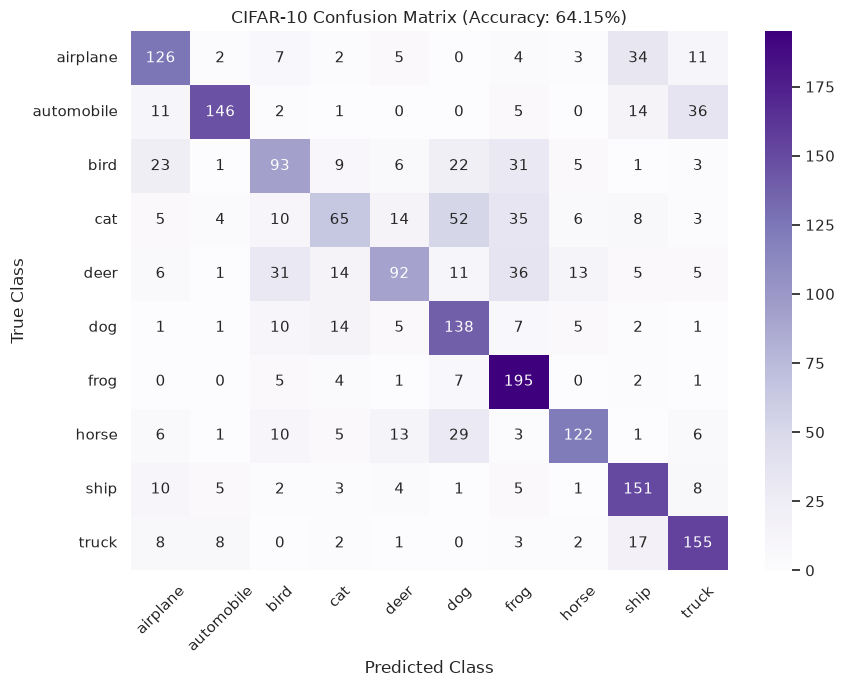

In [25]:
# 6, 7 & 8. Predict, Evaluation & Visualization
model_cifar.eval()
all_preds_cifar = []
all_targets_cifar = []

with torch.no_grad():
    for images, labels in test_loader_cifar:
        images = images.to(device)
        preds = model_cifar(images).argmax(dim=1)
        all_preds_cifar.extend(preds.cpu().numpy())
        all_targets_cifar.extend(labels.numpy())

all_preds_cifar = np.array(all_preds_cifar)
all_targets_cifar = np.array(all_targets_cifar)
acc_cifar = accuracy_score(all_targets_cifar, all_preds_cifar)

print("=" * 60)
print("CIFAR-10 FINAL EVALUATION REPORT")
print("=" * 60)
print(f"Best Checkpoint Test Accuracy: {acc_cifar * 100:.2f}%")
print(classification_report(all_targets_cifar, all_preds_cifar, target_names=cifar_classes, digits=4))

# Confusion Matrix Heatmap
plt.figure(figsize=(9, 7))
cm_cifar = confusion_matrix(all_targets_cifar, all_preds_cifar)
sns.heatmap(cm_cifar, annot=True, fmt="d", cmap="Purples", xticklabels=cifar_classes, yticklabels=cifar_classes)
plt.title(f"CIFAR-10 Confusion Matrix (Accuracy: {acc_cifar*100:.2f}%)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


---
# 6. Comparative Architecture Summary & Selection Guide

| Dimension | Multi-Layer Perceptron (MLP) | Convolutional Neural Network (CNN) | Recurrent Neural Network (RNN) | Long Short-Term Memory (LSTM) |
|---|---|---|---|---|
| **Primary Domain** | Tabular data, simple vectors | Images, video, grid-structured 2D/3D data | Short sequential sequences | Long-range textual & temporal sequences |
| **Input Structure** | 1D Flattened vector $(B, D)$ | 2D/3D Tensors $(B, C, H, W)$ | Sequential series $(B, T, D)$ | Sequential series $(B, T, D)$ |
| **Key Operation** | Matrix multiplication $\mathbf{W}\mathbf{x} + \mathbf{b}$ | Cross-correlation convolution & pooling | Hidden state recurrence $\mathbf{W}_{hh}\mathbf{h}_{t-1}$ | Additive gated memory cell highway |
| **Spatial Awareness** | ❌ None (destroys pixel topology) | ✅ Translation invariant, local filters | ❌ None | ❌ None |
| **Temporal Memory** | ❌ None | ❌ None | ⚠️ Short-range memory only | ✅ Long-range gating (forget/input/output) |
| **Vanishing Gradient** | Moderate (mitigated by ReLU) | Low (mitigated by BatchNorm/ResNets) | ❌ Critical flaw across timesteps | ✅ Solved by additive cell state |
| **Parameter Efficiency**| Low (dense all-to-all connectivity) | High (weight sharing across spatial grid) | Moderate | Higher (4 gates per cell) |

---

### Architectural Selection Decision Matrix:
- **Choose an MLP when:** Working with independent tabular rows, flat numerical feature vectors, or as a small classification head at the end of deep feature extractors.
- **Choose a CNN when:** Working with spatially correlated data (medical imaging, document OCR, satellite imagery, spectrogram audio).
- **Choose an RNN when:** Sequences are very short ($T < 10$) and computational latency/budget is constrained.
- **Choose an LSTM when:** Sequences have long-range dependencies (machine translation, sentiment analysis, stock forecasting, speech recognition).


---
# 7. Curated Learning Resources & References

Mastering Deep Learning requires both theoretical mathematical grounding and hands-on implementation practice. Below is a curated collection of world-class educational resources:

---

## 🎥 Video Courses & Tutorials

### 1. Andrej Karpathy — "Neural Networks: Zero to Hero"
Former Director of AI at Tesla and OpenAI founding scientist Andrej Karpathy teaches deep learning from complete scratch in pure Python and PyTorch.

| # | Topic | Key Concepts | Direct Link |
|---|---|---|---|
| 1 | **The Spelled-Out Intro to Neural Networks and Backpropagation** | Building `micrograd`, scalar autograd, chain rule, forward/backward pass | [Watch on YouTube](https://www.youtube.com/watch?v=VMj-3S1tku0) |
| 2 | **The Spelled-Out Intro to Language Modeling: Building makemore** | Bigram character models, negative log likelihood, PyTorch tensors | [Watch on YouTube](https://www.youtube.com/watch?v=PaCmpygFfXo) |
| 3 | **Building makemore Part 2: MLP** | Bengio et al. 2003 paper, embeddings, matrix multiplication, cross-entropy | [Watch on YouTube](https://www.youtube.com/watch?v=TCH_1BHY58I) |
| 4 | **Building makemore Part 3: Activations & Gradients, BatchNorm** | Kaiming init, activation saturation, dead ReLUs, Batch Normalization math | [Watch on YouTube](https://www.youtube.com/watch?v=P6sfmUTpUmc) |
| 5 | **Building makemore Part 4: Becoming a Backprop Ninja** | Deriving manual backward pass through linear layers, batchnorm, cross-entropy | [Watch on YouTube](https://www.youtube.com/watch?v=q8SA3rM6ckI) |
| 6 | **Building makemore Part 5: Building a WaveNet** | Dilated causal convolutions, tree hierarchies, efficient batching | [Watch on YouTube](https://www.youtube.com/watch?v=t3YJ5hKiMQ0) |
| 7 | **Let's Build GPT: from Scratch, in Code, Spelled Out** | Self-Attention, Multi-Head Attention, Residual connections, Transformers | [Watch on YouTube](https://www.youtube.com/watch?v=kCc8FmEb1nY) |
| 8 | **Let's Build the GPT Tokenizer** | Byte Pair Encoding (BPE), token vocabularies, regex splitting | [Watch on YouTube](https://www.youtube.com/watch?v=zduSFxRajkE) |
| 9 | **Let's Reproduce GPT-2 (124M)** | PyTorch DDP, mixed precision (bf16), FlashAttention, optimizer tuning | [Watch on YouTube](https://www.youtube.com/watch?v=l8pRSuU81PU) |

### 2. 3Blue1Brown — "Neural Networks" Series
Grant Sanderson's renowned visual mathematics channel provides intuitive geometric visualizations:
- [Chapter 1: But what is a neural network?](https://www.youtube.com/watch?v=aircAruvnKk) — Visualizing high-dimensional activation landscapes.
- [Chapter 2: Gradient descent, how neural networks learn](https://www.youtube.com/watch?v=IHZwWFHWa-w) — Visualizing loss valleys and parameter trajectories.
- [Chapter 3: What is backpropagation really doing?](https://www.youtube.com/watch?v=Ilg3gGewQ5U) — Tracing error signals backward.
- [Chapter 4: Backpropagation calculus](https://www.youtube.com/watch?v=tIeHLnjs5U8) — Formal mathematical derivation of chain rule gradients.

### 3. Stanford University Academic Courses (Free on YouTube)
- **Stanford CS231n: Deep Learning for Computer Vision** (Fei-Fei Li, Justin Johnson, Serena Yeung) — [YouTube Playlist](https://www.youtube.com/playlist?list=PL3FW7Lu3i5JvHM8ljYj-zLfQRF3EO8sYv)
- **Stanford CS224n: Natural Language Processing with Deep Learning** (Christopher Manning) — [YouTube Playlist](https://www.youtube.com/playlist?list=PLoROMvodv4rOSH4v6133s9LFPRHjEmbmJ)

---

## 📝 Written Guides & Classic Blog Posts
- **Andrej Karpathy:** [Yes you should understand backprop](https://karpathy.medium.com/yes-you-should-understand-backprop-e034f7dafdb0) — Why abstracting away backpropagation leads to subtle bugs.
- **Andrej Karpathy:** [The Unreasonable Effectiveness of Recurrent Neural Networks](https://karpathy.github.io/2015/05/21/rnn-effectiveness/) — A classic essay demonstrating character-level RNN text generation.
- **Andrej Karpathy:** [A Recipe for Training Neural Networks](https://karpathy.github.io/2019/04/25/recipe/) — Systematic checklist for training models without tears.
- **Christopher Olah:** [Understanding LSTM Networks](https://colah.github.io/posts/2015-08-Understanding-LSTMs/) — The definitive illustrated walkthrough of LSTM gate mechanisms.
- **Jay Alammar:** [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/) — Visual guide to attention mechanisms and Transformers.

---

## 📚 Free Online Textbooks
- **Deep Learning** by Ian Goodfellow, Yoshua Bengio, and Aaron Courville: [deeplearningbook.org](https://www.deeplearningbook.org/)
- **Dive into Deep Learning (D2L.ai)** by Aston Zhang, Zack C. Lipton, Mu Li, Alexander J. Smola: [d2l.ai](https://d2l.ai/) — Interactive textbook with live code in PyTorch, JAX, and TensorFlow.
- **Neural Networks and Deep Learning** by Michael Nielsen: [neuralnetworksanddeeplearning.com](http://neuralnetworksanddeeplearning.com/)

---

## 🔬 Foundational Research Papers
1. **Backpropagation (1986):** Rumelhart, Hinton, & Williams — *"Learning representations by back-propagating errors"* ([Nature](https://www.nature.com/articles/323533a0))
2. **Convolutional Networks (1998):** LeCun et al. — *"Gradient-based learning applied to document recognition"* ([IEEE](http://yann.lecun.com/exdb/publis/pdf/lecun-01a.pdf))
3. **LSTM (1997):** Hochreiter & Schmidhuber — *"Long Short-Term Memory"* ([Neural Computation](https://www.bioinf.jku.at/publications/older/2604.pdf))
4. **AlexNet (2012):** Krizhevsky, Sutskever, & Hinton — *"ImageNet Classification with Deep Convolutional Neural Networks"* ([NeurIPS](https://papers.nips.cc/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html))
5. **Adam Optimizer (2014):** Kingma & Ba — *"Adam: A Method for Stochastic Optimization"* ([arXiv:1412.6980](https://arxiv.org/abs/1412.6980))
6. **Batch Normalization (2015):** Ioffe & Szegedy — *"Batch Normalization: Accelerating Deep Network Training"* ([arXiv:1502.03167](https://arxiv.org/abs/1502.03167))
7. **Attention Is All You Need (2017):** Vaswani et al. — *"Attention Is All You Need"* ([arXiv:1706.03762](https://arxiv.org/abs/1706.03762))
